In [4]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.sequence import pad_sequences
from keras.utils import to_categorical
import numpy as np
from numpy import array
import pandas as pd
import cv2
from glob import glob
import PIL
import time
from tqdm import tqdm
import os

In [7]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print(f"\nFolder: {root}")
    print("Subfolders:", dirs[:8])
    print("Files:", files[:8])



Folder: /kaggle/input
Subfolders: ['datasets']
Files: []

Folder: /kaggle/input/datasets
Subfolders: ['raddar', 'sinamhd9']
Files: []

Folder: /kaggle/input/datasets/raddar
Subfolders: ['chest-xrays-indiana-university']
Files: []

Folder: /kaggle/input/datasets/sinamhd9
Subfolders: ['chexnet-weights']
Files: []


In [8]:

import os
import pandas as pd

base_path = (
    "/kaggle/input/datasets/raddar/"
    "chest-xrays-indiana-university"
)

projections = pd.read_csv(
    os.path.join(base_path, "indiana_projections.csv")
)

reports = pd.read_csv(
    os.path.join(base_path, "indiana_reports.csv")
)

print("PROJECTIONS")
print("Shape:", projections.shape)
print("Columns:", projections.columns.tolist())
display(projections.head(3))

print("\nREPORTS")
print("Shape:", reports.shape)
print("Columns:", reports.columns.tolist())
display(reports.head(3))


PROJECTIONS
Shape: (7466, 3)
Columns: ['uid', 'filename', 'projection']


,uid,filename,projection
0,1,1_IM-0001-4001.dcm.png,Frontal
1,1,1_IM-0001-3001.dcm.png,Lateral
2,2,2_IM-0652-1001.dcm.png,Frontal



REPORTS
Shape: (3851, 8)
Columns: ['uid', 'MeSH', 'Problems', 'image', 'indication', 'comparison', 'findings', 'impression']


,uid,MeSH,Problems,image,indication,comparison,findings,impression
0,1,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.
1,2,Cardiomegaly/borderline;Pulmonary Artery/enlarged,Cardiomegaly;Pulmonary Artery,"Chest, 2 views, frontal and lateral",Preop bariatric surgery.,None.,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.
2,3,normal,normal,Xray Chest PA and Lateral,"rib pain after a XXXX, XXXX XXXX steps this XX...",NaN,NaN,"No displaced rib fractures, pneumothorax, or p..."


In [9]:

import os
from pathlib import Path

# Search for chest X-ray images in Kaggle inputs
input_path = Path("/kaggle/input")

image_extensions = {".png", ".jpg", ".jpeg"}
image_paths = []

for path in input_path.rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        image_paths.append(str(path))

print("Total image files found:", len(image_paths))
print("\nFirst 10 image paths:")

for path in image_paths[:10]:
    print(path)

# Inspect projection metadata
print("\nProjection columns:", projections.columns.tolist())
display(projections.head(5))


Total image files found: 7470

First 10 image paths:
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/349_IM-1697-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/607_IM-2196-1001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/2832_IM-1249-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/699_IM-2263-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/1931_IM-0602-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/947_IM-2442-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/2932_IM-1335-1001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/2303_IM-0882-1001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-unive

,uid,filename,projection
0,1,1_IM-0001-4001.dcm.png,Frontal
1,1,1_IM-0001-3001.dcm.png,Lateral
2,2,2_IM-0652-1001.dcm.png,Frontal
3,2,2_IM-0652-2001.dcm.png,Lateral
4,3,3_IM-1384-1001.dcm.png,Frontal


In [10]:
INPUT_PATH = Path("/kaggle/input")
image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}
image_paths = [
    p for p in INPUT_PATH.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]
print("Image files found:", len(image_paths))
for p in image_paths[:10]:
    print(p)

if not image_paths:
    raise FileNotFoundError(
        "No image files were found under /kaggle/input. Check whether the image "
        "archive/dataset was added to this Kaggle notebook."
    )


Image files found: 7470
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/349_IM-1697-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/607_IM-2196-1001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/2832_IM-1249-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/699_IM-2263-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/1931_IM-0602-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/947_IM-2442-2001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/2932_IM-1335-1001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/2303_IM-0882-1001.dcm.png
/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalize

In [11]:
# ## 4. Build image filename lookup and match projection rows
# This uses the real filenames discovered above instead of assuming a directory structure.

# %%
image_lookup = {}
for p in image_paths:
    # Keep the first occurrence for duplicate basenames.
    image_lookup.setdefault(p.name.lower(), str(p))

print("Unique image basenames:", len(image_lookup))

# Detect a likely filename column in the projections table.
filename_candidates = [
    c for c in projections.columns
    if c.lower() in {"filename", "file_name", "image", "image_name", "path", "image_path"}
]
if not filename_candidates:
    filename_candidates = [
        c for c in projections.columns
        if projections[c].dtype == "object"
        and projections[c].astype(str).str.contains(r"\.(png|jpg|jpeg)$", case=False, regex=True).any()
    ]

if not filename_candidates:
    raise ValueError(
        "Could not identify a filename column in projections. "
        f"Columns available: {projections.columns.tolist()}"
    )

filename_col = filename_candidates[0]
print("Using filename column:", filename_col)

def locate_image(value):
    if pd.isna(value):
        return None
    raw = str(value).strip()
    # Direct path if a full path is stored.
    candidate = Path(raw)
    if candidate.is_file():
        return str(candidate)
    # Try basename.
    return image_lookup.get(candidate.name.lower())

projections = projections.copy()
projections["image_path"] = projections[filename_col].apply(locate_image)

print("Projection rows with matched images:", projections["image_path"].notna().sum())
display(projections[[filename_col, "image_path"]].head(10))

Unique image basenames: 7470
Using filename column: filename
Projection rows with matched images: 7466


,filename,image_path
0,1_IM-0001-4001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
1,1_IM-0001-3001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
2,2_IM-0652-1001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
3,2_IM-0652-2001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
4,3_IM-1384-1001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
5,3_IM-1384-2001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
6,4_IM-2050-1001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
7,4_IM-2050-2001.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
8,5_IM-2117-1003002.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...
9,5_IM-2117-1004003.dcm.png,/kaggle/input/datasets/raddar/chest-xrays-indi...


In [12]:
# %% [markdown]
# ## 5. Match image records to radiology reports
# Use a shared identifier if one is available; otherwise infer it from the filename
# only when the columns support that relationship.

# %%
common_columns = [c for c in projections.columns if c in reports.columns]
print("Shared columns:", common_columns)

# Prefer a shared UID-like key.
uid_candidates = [
    c for c in common_columns
    if c.lower() in {"uid", "study_id", "studyid", "report_id", "id"}
]
if uid_candidates:
    join_col = uid_candidates[0]
    print("Merging on:", join_col)
    data = projections.merge(reports, on=join_col, how="inner", suffixes=("_image", "_report"))
else:
    raise ValueError(
        "No shared UID/study ID column found between projections and reports. "
        "Inspect the printed columns and set join_col manually to the correct shared key."
    )

data = data[data["image_path"].notna()].copy()
data = data.drop_duplicates(subset=["image_path"]).reset_index(drop=True)
print("Rows after image/report matching:", len(data))
display(data.head(3))

Shared columns: ['uid']
Merging on: uid
Rows after image/report matching: 7466


,uid,filename,projection,image_path,MeSH,Problems,image,indication,comparison,findings,impression
0,1,1_IM-0001-4001.dcm.png,Frontal,/kaggle/input/datasets/raddar/chest-xrays-indi...,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.
1,1,1_IM-0001-3001.dcm.png,Lateral,/kaggle/input/datasets/raddar/chest-xrays-indi...,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.
2,2,2_IM-0652-1001.dcm.png,Frontal,/kaggle/input/datasets/raddar/chest-xrays-indi...,Cardiomegaly/borderline;Pulmonary Artery/enlarged,Cardiomegaly;Pulmonary Artery,"Chest, 2 views, frontal and lateral",Preop bariatric surgery.,None.,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.


In [14]:

# %% [markdown]
# ## 6. Create target report text

# %%
MAX_REPORTS = 500  # Use 500 records for initial testing; use None for all

lower_to_original = {c.lower(): c for c in data.columns}

# Identify available report text columns
text_candidates = [
    "findings",
    "impression",
    "report",
    "report_text",
    "description",
    "text"
]

available_text_cols = [
    lower_to_original[c]
    for c in text_candidates
    if c in lower_to_original
]

if not available_text_cols:
    raise ValueError(
        "No report text columns found. Available columns: "
        f"{data.columns.tolist()}"
    )

print("Text columns considered:", available_text_cols)


def clean_text_value(value):
    if pd.isna(value):
        return ""
    return " ".join(str(value).strip().split())


def combine_report(row):
    parts = []

    for col in available_text_cols:
        value = clean_text_value(row[col])

        if (
            value
            and value.lower() not in {"nan", "none", "null"}
            and value not in parts
        ):
            parts.append(value)

    return " ".join(parts)


# Combine findings and impression into one report
data = data.copy()
data["report_text"] = data.apply(combine_report, axis=1)

# Remove records without report text
data = data[data["report_text"].str.len() > 0].copy()
data = data.reset_index(drop=True)

# Limit records for initial testing
if MAX_REPORTS is not None:
    data = data.head(MAX_REPORTS).copy()

print("Rows with non-empty report text:", len(data))
print("Available report columns:", available_text_cols)

display(data[["image_path", "report_text"]].head(5))

# Validate the dataset before proceeding
if len(data) < 10:
    raise ValueError(
        "Fewer than 10 image/report pairs found. "
        "Check the image matching, join key, and report text columns."
    )

print("Section 6 completed successfully!")


Text columns considered: ['findings', 'impression', 'report_text']
Rows with non-empty report text: 500
Available report columns: ['findings', 'impression', 'report_text']


,image_path,report_text
0,/kaggle/input/datasets/raddar/chest-xrays-indi...,The cardiac silhouette and mediastinum size ar...
1,/kaggle/input/datasets/raddar/chest-xrays-indi...,The cardiac silhouette and mediastinum size ar...
2,/kaggle/input/datasets/raddar/chest-xrays-indi...,Borderline cardiomegaly. Midline sternotomy XX...
3,/kaggle/input/datasets/raddar/chest-xrays-indi...,Borderline cardiomegaly. Midline sternotomy XX...
4,/kaggle/input/datasets/raddar/chest-xrays-indi...,"No displaced rib fractures, pneumothorax, or p..."


Section 6 completed successfully!


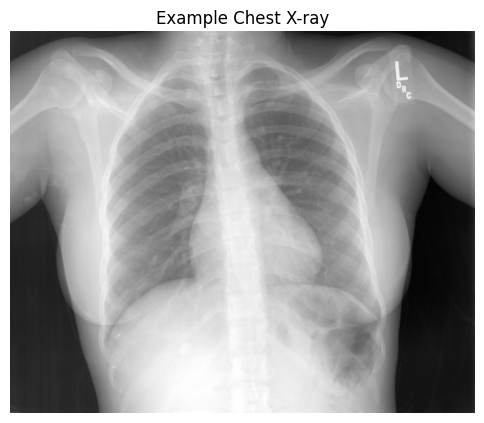

Radiology Report:
The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax. Normal chest x-XXXX. The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax. Normal chest x-XXXX.


In [15]:

# %% [markdown]
# ## 7. Inspect one matched X-ray and its report

# %%
import matplotlib.pyplot as plt
from PIL import Image

# Select one image/report pair
sample = data.iloc[0]

# Display the chest X-ray
with Image.open(sample["image_path"]) as img:
    plt.figure(figsize=(6, 6))
    plt.imshow(img.convert("RGB"), cmap="gray")
    plt.axis("off")
    plt.title("Example Chest X-ray")
    plt.show()

# Display its corresponding radiology report
print("Radiology Report:")
print(sample["report_text"])


In [16]:

# %% [markdown]
# ## 8. Split data into training and validation sets

# %%
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
VALIDATION_SIZE = 0.15

# Identify a suitable grouping column to reduce data leakage
group_candidates = [
    "patient_id",
    "subject_id",
    "uid",
    "study_id",
    "studyid"
]

group_col = next(
    (
        col for col in data.columns
        if col.lower() in group_candidates
    ),
    None
)

if group_col is not None and data[group_col].nunique() > 1:

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_SIZE,
        random_state=SEED
    )

    train_idx, val_idx = next(
        splitter.split(data, groups=data[group_col])
    )

    train_df = data.iloc[train_idx].reset_index(drop=True)
    val_df = data.iloc[val_idx].reset_index(drop=True)

else:
    # Fallback when no usable grouping column exists
    shuffled = data.sample(
        frac=1,
        random_state=SEED
    ).reset_index(drop=True)

    split_at = int(len(shuffled) * (1 - VALIDATION_SIZE))

    train_df = shuffled.iloc[:split_at].reset_index(drop=True)
    val_df = shuffled.iloc[split_at:].reset_index(drop=True)

# Display split information
print("Total image/report pairs:", len(data))
print("Training pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Grouping column:", group_col)

print("\nTraining sample:")
display(train_df[["image_path", "report_text"]].head(3))

print("\nValidation sample:")
display(val_df[["image_path", "report_text"]].head(3))

# Validate the split
if len(train_df) == 0 or len(val_df) == 0:
    raise ValueError(
        "Training or validation set is empty. "
        "Check the number of matched image/report pairs."
    )

print("\nSection 8 completed successfully!")


Total image/report pairs: 500
Training pairs: 423
Validation pairs: 77
Grouping column: uid

Training sample:


,image_path,report_text
0,/kaggle/input/datasets/raddar/chest-xrays-indi...,The cardiac silhouette and mediastinum size ar...
1,/kaggle/input/datasets/raddar/chest-xrays-indi...,The cardiac silhouette and mediastinum size ar...
2,/kaggle/input/datasets/raddar/chest-xrays-indi...,Borderline cardiomegaly. Midline sternotomy XX...



Validation sample:


,image_path,report_text
0,/kaggle/input/datasets/raddar/chest-xrays-indi...,The cardiac contours are normal. XXXX basilar ...
1,/kaggle/input/datasets/raddar/chest-xrays-indi...,The cardiac contours are normal. XXXX basilar ...
2,/kaggle/input/datasets/raddar/chest-xrays-indi...,The cardiomediastinal silhouette is within nor...



Section 8 completed successfully!


In [21]:

# Section 9: Extract image features offline

import numpy as np
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

# Create DenseNet without downloading weights
encoder = DenseNet121(
    weights=None,
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)
encoder.trainable = False

def load_preprocess_image(path):
    with Image.open(path) as img:
        img = img.convert("RGB").resize(IMAGE_SIZE)
        arr = np.asarray(img, dtype=np.float32)
    return preprocess_input(arr)

def extract_features(df, batch_size=BATCH_SIZE):
    results = []

    for start in tqdm(range(0, len(df), batch_size)):
        batch = df.iloc[start:start + batch_size]

        images = np.stack([
            load_preprocess_image(path)
            for path in batch["image_path"]
        ])

        features = encoder.predict(images, verbose=0)
        results.append(features)

    return np.concatenate(results, axis=0)

train_features = extract_features(train_df)
val_features = extract_features(val_df)

print("Training features:", train_features.shape)
print("Validation features:", val_features.shape)
print("Section 9 completed!")


  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Training features: (423, 1024)
Validation features: (77, 1024)
Section 9 completed!


In [24]:

# %% [markdown]
# ## 10. Tokenize and prepare radiology reports

# %%
import re
import numpy as np
from collections import Counter
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Configuration
MAX_VOCAB_SIZE = 10000
MAX_SEQ_LENGTH = 100

PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
START_TOKEN = "<start>"
END_TOKEN = "<end>"

# Basic text tokenizer
def tokenize_report(text):
    text = str(text).lower().strip()
    tokens = re.findall(r"[a-z]+|[0-9]+(?:\.[0-9]+)?|[^\w\s]", text)
    return tokens

# Build vocabulary using training reports only
token_counts = Counter()

for report in train_df["report_text"].fillna(""):
    token_counts.update(tokenize_report(report))

special_tokens = [
    PAD_TOKEN,
    UNK_TOKEN,
    START_TOKEN,
    END_TOKEN
]

most_common_tokens = [
    token for token, count in token_counts.most_common(
        MAX_VOCAB_SIZE - len(special_tokens)
    )
    if token not in special_tokens
]

vocabulary = special_tokens + most_common_tokens

word_to_id = {
    word: idx for idx, word in enumerate(vocabulary)
}

id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

PAD_ID = word_to_id[PAD_TOKEN]
UNK_ID = word_to_id[UNK_TOKEN]
START_ID = word_to_id[START_TOKEN]
END_ID = word_to_id[END_TOKEN]

print("Vocabulary size:", len(vocabulary))


# Convert a report into a sequence of token IDs
def encode_report(text):
    tokens = tokenize_report(text)
    tokens = [START_TOKEN] + tokens + [END_TOKEN]

    token_ids = [
        word_to_id.get(token, UNK_ID)
        for token in tokens
    ]

    return token_ids[:MAX_SEQ_LENGTH]


# Encode and pad training and validation reports
train_sequences = [
    encode_report(report)
    for report in train_df["report_text"].fillna("")
]

val_sequences = [
    encode_report(report)
    for report in val_df["report_text"].fillna("")
]

train_captions = pad_sequences(
    train_sequences,
    maxlen=MAX_SEQ_LENGTH,
    padding="post",
    truncating="post",
    value=PAD_ID
)

val_captions = pad_sequences(
    val_sequences,
    maxlen=MAX_SEQ_LENGTH,
    padding="post",
    truncating="post",
    value=PAD_ID
)

print("Training caption shape:", train_captions.shape)
print("Validation caption shape:", val_captions.shape)


# Decode one sequence to inspect the preprocessing
def decode_sequence(sequence):
    words = []

    for token_id in sequence:
        word = id_to_word[int(token_id)]

        if word == END_TOKEN:
            break

        if word not in {PAD_TOKEN, START_TOKEN}:
            words.append(word)

    return " ".join(words)


print("\nOriginal training report:")
print(train_df.iloc[0]["report_text"])

print("\nProcessed training report:")
print(decode_sequence(train_captions[0]))

print("\nSection 10 completed successfully!")


Vocabulary size: 734
Training caption shape: (423, 100)
Validation caption shape: (77, 100)

Original training report:
The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax. Normal chest x-XXXX. The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax. Normal chest x-XXXX.

Processed training report:
the cardiac silhouette and mediastinum size are within normal limits . there is no pulmonary edema . there is no focal consolidation . there are no xxxx of a pleural effusion . there is no evidence of pneumothorax . normal chest x - xxxx . the cardiac silhouette and mediastinum size are within normal limits . there is no pulmonary edema . there is no focal consolidation . there are no x

In [23]:

# %% [markdown]
# ## 11. Build the image-to-report generation model

# %%
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Dense, Embedding, LSTM,
    Dropout, Add, Concatenate
)
from tensorflow.keras.models import Model

# Configuration
EMBEDDING_DIM = 256
LSTM_UNITS = 256
FEATURE_DIM = int(train_features.shape[1])
VOCAB_SIZE = len(vocabulary)

# Image feature input
image_input = Input(
    shape=(FEATURE_DIM,),
    name="image_features"
)

# Project image features into the decoder's hidden representation
image_embedding = Dense(
    LSTM_UNITS,
    activation="relu",
    name="image_projection"
)(image_input)

image_embedding = Dropout(0.3)(image_embedding)

# Text input: report tokens excluding the final token
text_input = Input(
    shape=(MAX_SEQ_LENGTH - 1,),
    name="report_tokens"
)

text_embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=False,
    name="word_embedding"
)(text_input)

# Repeat the image representation across the text sequence
image_context = tf.keras.layers.RepeatVector(
    MAX_SEQ_LENGTH - 1
)(image_embedding)

# Combine image information with the text embeddings
decoder_input = Concatenate(axis=-1)(
    [text_embedding, image_context]
)

decoder_output = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    name="report_decoder"
)(decoder_input)

decoder_output = Dropout(0.3)(decoder_output)

# Predict the next word at each time step
word_predictions = Dense(
    VOCAB_SIZE,
    activation="softmax",
    name="word_predictions"
)(decoder_output)

model = Model(
    inputs=[image_input, text_input],
    outputs=word_predictions
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

model.summary()

print("Section 11 completed successfully!")


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 1024)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_projection    │ (None, 256)       │    262,400 │ image_features[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ report_tokens       │ (None, 99)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ image_projection… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 99, 256)   │    187,904 │ report_tokens[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 99, 256)   │          0 │ dropout[0][0]     │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 99, 512)   │          0 │ word_embedding[0… │
│ (Concatenate)       │                   │            │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ report_decoder      │ (None, 99, 256)   │    787,456 │ concatenate[0][0] │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 99, 256)   │          0 │ report_decoder[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_predictions    │ (None, 99, 734)   │    188,638 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,426,398 (5.44 MB)

 Trainable params: 1,426,398 (5.44 MB)

 Non-trainable params: 0 (0.00 B)

Section 11 completed successfully!


In [25]:

# %% [markdown]
# ## 12. Prepare sequences and train the model

# %%
import numpy as np
import tensorflow as tf

# Prepare next-word prediction sequences
# Input:  <start> word1 word2 ...
# Target: word1   word2 ... <end>

X_train_text = train_captions[:, :-1]
y_train = train_captions[:, 1:]

X_val_text = val_captions[:, :-1]
y_val = val_captions[:, 1:]

# Image features are paired with their corresponding reports
X_train_image = train_features.astype(np.float32)
X_val_image = val_features.astype(np.float32)

# Ignore padding tokens when calculating the loss
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    reduction="none"
)

def masked_loss(y_true, y_pred):
    per_token_loss = loss_function(y_true, y_pred)

    mask = tf.cast(
        tf.not_equal(y_true, PAD_ID),
        per_token_loss.dtype
    )

    return tf.reduce_sum(per_token_loss * mask) / (
        tf.reduce_sum(mask) + tf.keras.backend.epsilon()
    )

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_loss,
    metrics=["sparse_categorical_accuracy"]
)

print("Training image features:", X_train_image.shape)
print("Training text inputs:", X_train_text.shape)
print("Training targets:", y_train.shape)

print("Validation image features:", X_val_image.shape)
print("Validation text inputs:", X_val_text.shape)
print("Validation targets:", y_val.shape)

# Train the model
history = model.fit(
    [X_train_image, X_train_text],
    y_train,
    validation_data=(
        [X_val_image, X_val_text],
        y_val
    ),
    epochs=5,
    batch_size=16,
    verbose=1
)

print("Section 12 completed successfully!")


Training image features: (423, 1024)
Training text inputs: (423, 99)
Training targets: (423, 99)
Validation image features: (77, 1024)
Validation text inputs: (77, 99)
Validation targets: (77, 99)
Epoch 1/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 299ms/step - loss: 5.2798 - sparse_categorical_accuracy: 0.0896 - val_loss: 4.7732 - val_sparse_categorical_accuracy: 0.1042
Epoch 2/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 296ms/step - loss: 4.6180 - sparse_categorical_accuracy: 0.1182 - val_loss: 4.4432 - val_sparse_categorical_accuracy: 0.1371
Epoch 3/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 287ms/step - loss: 4.2050 - sparse_categorical_accuracy: 0.1599 - val_loss: 3.9952 - val_sparse_categorical_accuracy: 0.2104
Epoch 4/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 283ms/step - loss: 3.7604 - sparse_categorical_accuracy: 0.2163 - val_loss: 3.6099 - val_sparse_categorical_accuracy: 0.2381
Epoch 5/5
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 281ms/step - loss: 3.4156 - sparse_categorical_accuracy: 0.2457 - val_loss: 3.3709 - val_sparse_catego

Training history:


,loss,sparse_categorical_accuracy,val_loss,val_sparse_categorical_accuracy
0,5.279757,0.089620,4.773180,0.104158
1,4.617957,0.118156,4.443233,0.137085
2,4.205029,0.159945,3.995212,0.210416
3,3.760370,0.216348,3.609913,0.238095
4,3.415615,0.245743,3.370852,0.255805


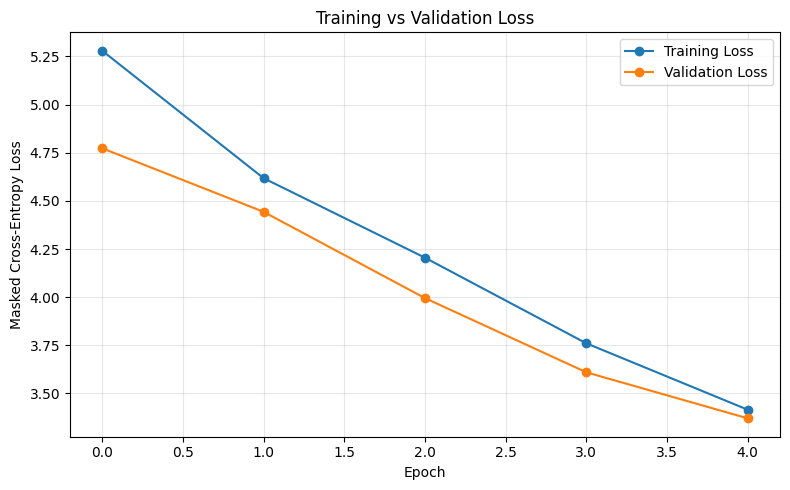

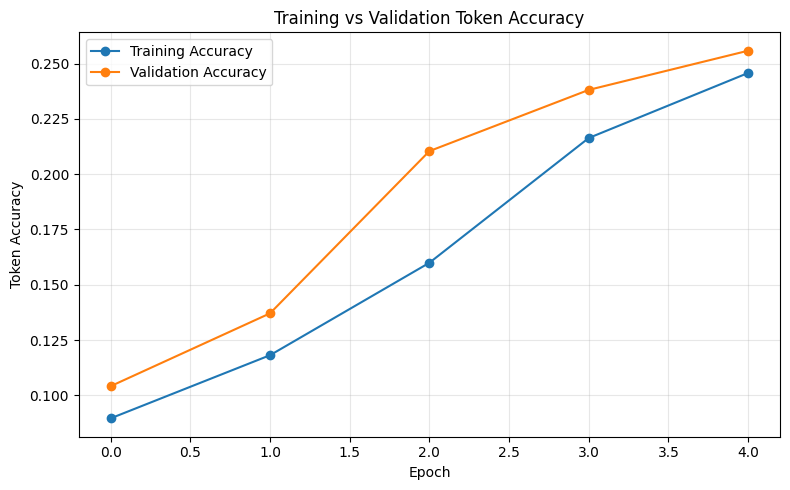

Section 13 completed successfully!


In [26]:

# %% [markdown]
# ## 13. Visualise training and validation performance

# %%
import matplotlib.pyplot as plt
import pandas as pd

# Convert training history into a DataFrame
history_df = pd.DataFrame(history.history)

print("Training history:")
display(history_df)

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Masked Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot token-level accuracy, if recorded
if (
    "sparse_categorical_accuracy" in history_df.columns
    and "val_sparse_categorical_accuracy" in history_df.columns
):
    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["sparse_categorical_accuracy"],
        marker="o",
        label="Training Accuracy"
    )

    plt.plot(
        history_df["val_sparse_categorical_accuracy"],
        marker="o",
        label="Validation Accuracy"
    )

    plt.title("Training vs Validation Token Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Token Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("Section 13 completed successfully!")


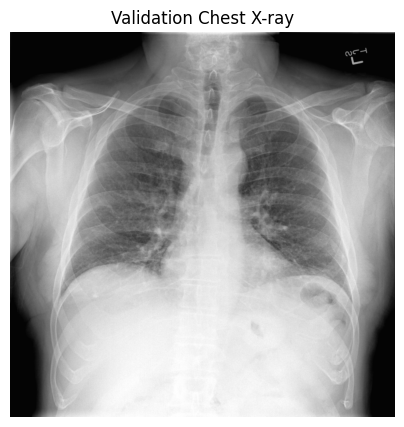

REFERENCE RADIOLOGY REPORT
The cardiac contours are normal. XXXX basilar atelectasis. The lungs are clear. Thoracic spondylosis. Lower cervical XXXX arthritis. Basilar atelectasis. No confluent lobar consolidation or pleural effusion. The cardiac contours are normal. XXXX basilar atelectasis. The lungs are clear. Thoracic spondylosis. Lower cervical XXXX arthritis. Basilar atelectasis. No confluent lobar consolidation or pleural effusion.

GENERATED REPORT
the heart size and mediastinum are normal . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no acute cardiopulmonary disease . no ac

In [27]:

# %% [markdown]
# ## 14. Generate a sample radiology report

# %%
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def generate_report(image_features, max_length=MAX_SEQ_LENGTH):
    # Begin generation with the start token
    sequence = [START_ID]

    for _ in range(max_length - 1):
        # Prepare the current token sequence
        padded_sequence = np.full(
            (1, MAX_SEQ_LENGTH - 1),
            PAD_ID,
            dtype=np.int32
        )

        current_tokens = sequence[:MAX_SEQ_LENGTH - 1]
        padded_sequence[0, :len(current_tokens)] = current_tokens

        # Predict next-word probabilities
        predictions = model.predict(
            [
                image_features.reshape(1, -1),
                padded_sequence
            ],
            verbose=0
        )

        # Use the prediction at the last existing token position
        position = len(current_tokens) - 1
        next_token_probs = predictions[0, position, :]

        # Greedy decoding: choose the most probable token
        next_token_id = int(np.argmax(next_token_probs))

        if next_token_id == END_ID:
            break

        # Avoid generating special tokens inside the report
        if next_token_id in (PAD_ID, START_ID):
            next_token_probs[PAD_ID] = 0
            next_token_probs[START_ID] = 0
            next_token_id = int(np.argmax(next_token_probs))

        sequence.append(next_token_id)

        if len(sequence) >= MAX_SEQ_LENGTH:
            break

    return decode_sequence(sequence)


# Select one validation example
sample_idx = 0
sample = val_df.iloc[sample_idx]
sample_features = val_features[sample_idx]

# Display the X-ray
with Image.open(sample["image_path"]) as img:
    plt.figure(figsize=(5, 5))
    plt.imshow(img.convert("RGB"), cmap="gray")
    plt.axis("off")
    plt.title("Validation Chest X-ray")
    plt.show()

# Generate and compare reports
generated_report = generate_report(sample_features)
reference_report = sample["report_text"]

print("=" * 60)
print("REFERENCE RADIOLOGY REPORT")
print("=" * 60)
print(reference_report)

print("\n" + "=" * 60)
print("GENERATED REPORT")
print("=" * 60)
print(generated_report)

print("\nSection 14 completed successfully!")


In [28]:

# %% [markdown]
# ## 15. Evaluate generated reports using text similarity

# %%
import numpy as np
import pandas as pd
from collections import Counter

# Simple BLEU-1 implementation (unigram precision with brevity penalty)
def calculate_bleu1(reference, candidate):
    ref_tokens = tokenize_report(reference)
    cand_tokens = tokenize_report(candidate)

    if not cand_tokens:
        return 0.0

    ref_counts = Counter(ref_tokens)
    cand_counts = Counter(cand_tokens)

    clipped_matches = sum(
        min(count, ref_counts[token])
        for token, count in cand_counts.items()
    )

    precision = clipped_matches / len(cand_tokens)

    if precision == 0:
        return 0.0

    brevity_penalty = min(
        1.0,
        np.exp(1 - len(ref_tokens) / len(cand_tokens))
    )

    return float(brevity_penalty * precision)


# ROUGE-L using longest common subsequence
def lcs_length(a, b):
    previous = [0] * (len(b) + 1)

    for token_a in a:
        current = [0] * (len(b) + 1)

        for j, token_b in enumerate(b, start=1):
            if token_a == token_b:
                current[j] = previous[j - 1] + 1
            else:
                current[j] = max(
                    previous[j],
                    current[j - 1]
                )

        previous = current

    return previous[-1]


def calculate_rouge_l(reference, candidate):
    ref_tokens = tokenize_report(reference)
    cand_tokens = tokenize_report(candidate)

    if not ref_tokens or not cand_tokens:
        return 0.0

    common = lcs_length(ref_tokens, cand_tokens)

    precision = common / len(cand_tokens)
    recall = common / len(ref_tokens)

    if precision + recall == 0:
        return 0.0

    return float(
        2 * precision * recall / (precision + recall)
    )


# Evaluate a subset of validation examples
N_EVAL = min(50, len(val_df))

evaluation_rows = []

for i in range(N_EVAL):
    reference = str(val_df.iloc[i]["report_text"])
    candidate = generate_report(val_features[i])

    evaluation_rows.append({
        "reference_report": reference,
        "generated_report": candidate,
        "BLEU_1": calculate_bleu1(reference, candidate),
        "ROUGE_L": calculate_rouge_l(reference, candidate)
    })

results_df = pd.DataFrame(evaluation_rows)

print("Number of reports evaluated:", len(results_df))
print("\nAverage text similarity metrics:")

display(
    results_df[["BLEU_1", "ROUGE_L"]]
    .mean()
    .to_frame("Mean score")
)

print("\nSample evaluation results:")
display(results_df.head(5))


Number of reports evaluated: 50

Average text similarity metrics:


,Mean score
BLEU_1,0.192697
ROUGE_L,0.219235



Sample evaluation results:


,reference_report,generated_report,BLEU_1,ROUGE_L
0,The cardiac contours are normal. XXXX basilar ...,the heart size and mediastinum are normal . no...,0.191919,0.227545
1,The cardiac contours are normal. XXXX basilar ...,the heart size and mediastinum are normal . no...,0.191919,0.227545
2,The cardiomediastinal silhouette is within nor...,the heart size and mediastinum are normal . no...,0.289985,0.271357
3,The cardiomediastinal silhouette is within nor...,the heart size and mediastinum are normal . no...,0.289985,0.271357
4,Cardiomediastinal silhouette and pulmonary vas...,the heart size and mediastinum are normal . no...,0.252525,0.314465


In [29]:

# %% [markdown]
# ## 16. Save the model and experiment results

# %%
import os
import json
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/chest_xray_report_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Save the report-generation model
model_path = os.path.join(
    OUTPUT_DIR,
    "report_generation_model.keras"
)

model.save(model_path)
print("Saved model:", model_path)

# 2. Save vocabulary and tokenization configuration
vocab_path = os.path.join(
    OUTPUT_DIR,
    "vocabulary.json"
)

with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "word_to_id": word_to_id,
            "id_to_word": {
                str(key): value
                for key, value in id_to_word.items()
            },
            "max_vocab_size": MAX_VOCAB_SIZE,
            "max_seq_length": MAX_SEQ_LENGTH,
            "pad_token": PAD_TOKEN,
            "unk_token": UNK_TOKEN,
            "start_token": START_TOKEN,
            "end_token": END_TOKEN
        },
        f,
        ensure_ascii=False,
        indent=2
    )

print("Saved vocabulary:", vocab_path)

# 3. Save evaluation results, if Section 15 has run
if "results_df" in globals():
    results_path = os.path.join(
        OUTPUT_DIR,
        "evaluation_results.csv"
    )
    results_df.to_csv(results_path, index=False)
    print("Saved evaluation results:", results_path)

    metrics = results_df[["BLEU_1", "ROUGE_L"]].mean().to_dict()

    metrics_path = os.path.join(
        OUTPUT_DIR,
        "evaluation_metrics.json"
    )

    with open(metrics_path, "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    print("Saved evaluation metrics:", metrics_path)

# 4. Save training history, if available
if "history" in globals():
    history_path = os.path.join(
        OUTPUT_DIR,
        "training_history.csv"
    )

    pd.DataFrame(history.history).to_csv(
        history_path,
        index=False
    )

    print("Saved training history:", history_path)

# 5. List saved files
print("\nFiles saved:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    full_path = os.path.join(OUTPUT_DIR, filename)
    print(f"{filename}: {os.path.getsize(full_path) / 1024:.2f} KB")

print("\nSection 16 completed successfully!")


Saved model: /kaggle/working/chest_xray_report_model/report_generation_model.keras
Saved vocabulary: /kaggle/working/chest_xray_report_model/vocabulary.json
Saved evaluation results: /kaggle/working/chest_xray_report_model/evaluation_results.csv
Saved evaluation metrics: /kaggle/working/chest_xray_report_model/evaluation_metrics.json
Saved training history: /kaggle/working/chest_xray_report_model/training_history.csv

Files saved:
evaluation_metrics.json: 0.07 KB
evaluation_results.csv: 60.59 KB
report_generation_model.keras: 16762.26 KB
training_history.csv: 0.44 KB
vocabulary.json: 30.88 KB

Section 16 completed successfully!
